
# Figure 4c — Preferred spatial wavenumber as a function of propagation velocity

This notebook analyzes the dependence of the dominant eigenvalue and preferred spatial wavenumber on propagation velocity, using results from the linear stability analysis of the spatially structured network.

For each propagation velocity, the notebook loads precomputed eigenvalue solutions obtained over a range of spatial wavenumbers $k_y$, with $k_x=0$. At each wavenumber, it identifies the largest real part among the eigenvalues found by the numerical solver, obtaining an estimate of the dominant growth rate $\mathrm{Re}(\lambda)$ as a function of $k_y$.

The resulting curves are interpolated using a cubic spline (or optionally PCHIP or linear interpolation). The preferred wavenumber $k^*$ is estimated as the location of the maximum interpolated growth rate. Repeating this procedure across propagation velocities gives the dependence of $k^*$ on velocity, as shown in Figure 4c.

The notebook generates two figures: the dominant eigenvalue real part as a function of wavenumber for different velocities, and the preferred wavenumber as a function of propagation velocity.

## Input data

The notebook requires precomputed MATLAB `.mat` files stored in `stability_results_velocities`, with one file per propagation velocity.


## Outputs

The notebook generates:

- `real_eigenvalues_vs_k.svg`: dominant growth-rate curves for the different velocities.
- `k_max_vs_velocity.svg`: preferred wavenumber as a function of velocity.

The peak locations and corresponding growth rates are also exported in MATLAB (`.mat`) and NumPy (`.npz`) formats.

For compatibility with previous MATLAB analyses, the saved variable `maxKx_per_param` contains the preferred wavenumbers, although the present analysis varies $k_y$ with $k_x=0$. The variable `unique_params` contains the propagation velocities in mm/ms.

## Notes

Missing eigenvalue solutions are represented by `NaN`, and interpolation is performed only over contiguous regions containing valid results.

The dominant growth rate is estimated from the eigenvalue roots returned by the numerical solver. Interpolation may introduce small shifts in the estimated maximum, particularly near changes in the dominant branch.

This notebook performs post-processing only; it does not compute the eigenvalue solutions themselves.

**Dependencies:** Python 3, NumPy, SciPy, Matplotlib.



In [1]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat, savemat
from scipy.interpolate import CubicSpline, PchipInterpolator

# Edit these settings.
DATA_DIR = Path("stability_results_velocities")  # Folder containing the velocity-sweep .mat files
OUTPUT_DIR = DATA_DIR
LIST_VEL = np.array([200, 300, 400, 500, 600,650, 700], dtype=float)  # mm/s
G = 3.30
NUEXT = 0.85
PT_MORE = 1000
INTERPOLATION = "spline"  # "spline", "pchip", or "linear"
FILENAME_PATTERN = (
    "Stability_peak_isotropy_2_nu_ext{nuext:.2f}_g{g:.2f}_v{velocity:.1f}.mat"
)
K_LABEL = r"$k_y$ [mm$^{-1}$]"
K_PEAK_LABEL = r"$k^*$ [mm$^{-1}$]"

orange = np.array([1.0, 0.8, 0.0])
purple = np.array([0.5, 0.0, 0.5])
colors = np.linspace(orange, purple, len(LIST_VEL))
plt.rcParams.update({"font.size": 18})
print("Reading from:", DATA_DIR.resolve())


Reading from: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/theory/Fig4_python/stability_results_velocities


In [2]:
def load_dominant_curve(path):
    # Keep the MATLAB cell structure, including empty and single-row cells.
    data = loadmat(path, squeeze_me=False)
    required = {"List_ky", "local_minima_all"}
    missing = required - data.keys()
    if missing:
        raise ValueError(f"{path.name}: missing variables {sorted(missing)}")
    k = np.asarray(data["List_ky"], dtype=float).ravel(order="F")
    cells = np.asarray(data["local_minima_all"], dtype=object).ravel(order="F")
    if k.size != cells.size or k.size == 0:
        raise ValueError(f"{path.name}: incompatible k vector and cell array lengths")
    if not np.all(np.isfinite(k)):
        raise ValueError(f"{path.name}: k values must be finite")
    real_part = np.full(k.size, np.nan)
    for i, cell in enumerate(cells):
        roots = np.asarray(cell, dtype=float)
        if roots.size == 0:
            continue
        if roots.ndim != 2 or roots.shape[1] < 1:
            raise ValueError(f"{path.name}: invalid root matrix at index {i}")
        values = roots[:, 0]
        values = values[np.isfinite(values)]
        if values.size:
            real_part[i] = values.max()
    order = np.argsort(k)
    k, real_part = k[order], real_part[order]
    if np.any(np.diff(k) <= 0):
        raise ValueError(f"{path.name}: k values must be distinct")
    return k, real_part


def interpolate_curve(k, real_part, method="spline", npoints=1000):
    """Interpolate contiguous finite runs without crossing missing-root gaps."""
    if method not in {"spline", "pchip", "linear"} or npoints < 2:
        raise ValueError("Choose spline/pchip/linear and npoints >= 2")
    valid_indices = np.flatnonzero(np.isfinite(real_part))
    if not valid_indices.size:
        return [], np.nan, np.nan
    runs = np.split(valid_indices, np.flatnonzero(np.diff(valid_indices) > 1) + 1)
    segments = []
    for indices in runs:
        x, y = k[indices], real_part[indices]
        if len(x) == 1:
            # Isolated valid points remain candidates for the peak.
            segments.append((x.copy(), y.copy()))
            continue
        xfine = np.linspace(x[0], x[-1], npoints)
        if method == "spline":
            # Not-a-knot cubic spline, corresponding to MATLAB interp1(...,'spline').
            yfine = CubicSpline(x, y, bc_type="not-a-knot")(xfine)
        elif method == "pchip":
            yfine = PchipInterpolator(x, y)(xfine)
        else:
            yfine = np.interp(xfine, x, y)
        segments.append((xfine, yfine))
    all_k = np.concatenate([segment[0] for segment in segments])
    all_real = np.concatenate([segment[1] for segment in segments])
    finite = np.flatnonzero(np.isfinite(all_real))
    if not finite.size:
        return segments, np.nan, np.nan
    peak_index = finite[np.argmax(all_real[finite])]
    return segments, float(all_k[peak_index]), float(all_real[peak_index])


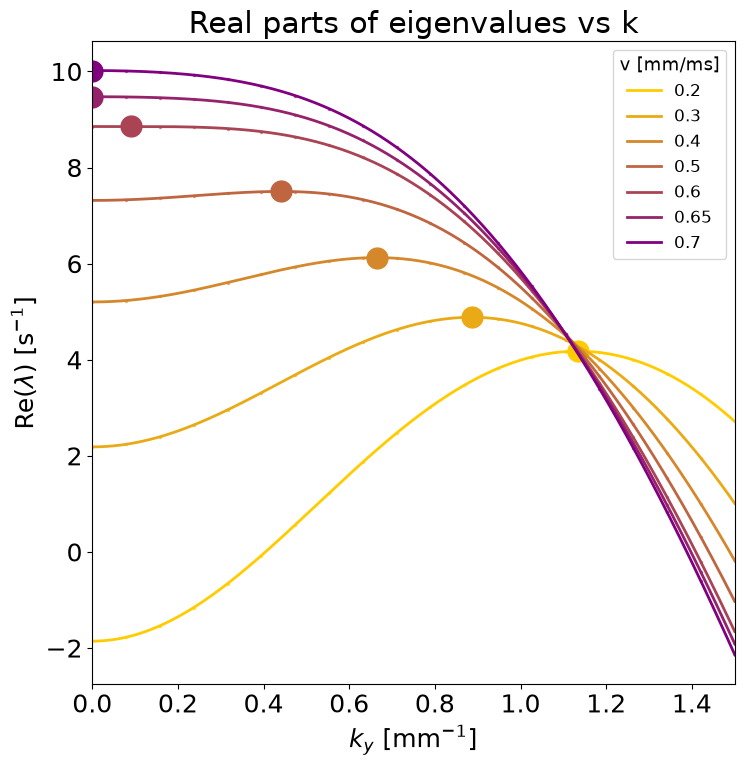

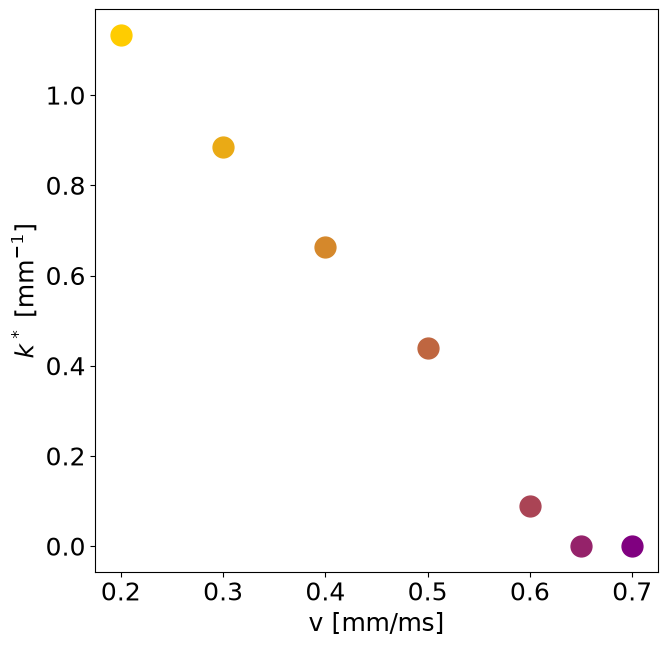

v [mm/s]    v [mm/ms]       k*          max Re(lambda)
   200.0        0.200       1.13363           4.17836
   300.0        0.300      0.885886           4.88361
   400.0        0.400      0.663664           6.12578
   500.0        0.500       0.43994           7.50282
   600.0        0.600     0.0900901           8.85459
   650.0        0.650             0           9.47455
   700.0        0.700             0           10.0192


In [3]:
k_max = np.full(len(LIST_VEL), np.nan)
max_real = np.full(len(LIST_VEL), np.nan)
 
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 8))
for array_id, velocity in enumerate(LIST_VEL):
    filename = FILENAME_PATTERN.format(nuext=NUEXT, g=G, velocity=velocity)
    path = DATA_DIR / filename
    if not path.is_file():
        warnings.warn(f"File not found: {path}", stacklevel=2)
        continue
    k, real_part = load_dominant_curve(path)
    segments, k_max[array_id], max_real[array_id] = interpolate_curve(
        k, real_part, method=INTERPOLATION, npoints=PT_MORE
    )
 
    if not segments:
        warnings.warn(f"No finite roots in {filename}", stacklevel=2)
        continue
    color = colors[array_id]
 #   ax.plot(k, real_part, ms=3, color=color, alpha=0.55)

    ax.plot(
    k, real_part, ".",
    linestyle="None",
    markersize=3,
    color=color,
    alpha=0.55
)
    
    for j, (k_fine, real_interp) in enumerate(segments):
        ax.plot(k_fine, real_interp, linewidth=2, color=color,
                label=f"{velocity / 1000:g}" if j == 0 else None)
    ax.plot(k_max[array_id], max_real[array_id], ".", color=color, markersize=30)

ax.set_xlim(0.0, 1.5)
ax.set_xlabel(K_LABEL)
ax.set_ylabel(r"Re($\lambda$) [s$^{-1}$]")
ax.set_title("Real parts of eigenvalues vs k")
ax.set_box_aspect(1)
if ax.get_legend_handles_labels()[0]:
    ax.legend(title="v [mm/ms]", fontsize=12, title_fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "real_eigenvalues_vs_k.svg",
            format="svg", bbox_inches="tight")
plt.show()

 

fig_peak, ax_peak = plt.subplots(figsize=(7, 7))
for i, velocity in enumerate(LIST_VEL):
    ax_peak.plot(
        velocity / 1000,
        k_max[i],
        ".",
        color=colors[i],
        markersize=30
    )
ax_peak.set_xlabel("v [mm/ms]")
ax_peak.set_ylabel(K_PEAK_LABEL)
ax_peak.set_box_aspect(1)
fig_peak.tight_layout()
fig_peak.savefig(OUTPUT_DIR / "k_max_vs_velocity.svg",
                 format="svg", bbox_inches="tight")
plt.show()
print("v [mm/s]    v [mm/ms]       k*          max Re(lambda)")
for velocity, peak_k, peak_real in zip(LIST_VEL, k_max, max_real):
    print(f"{velocity:8.1f}    {velocity/1000:9.3f}    {peak_k:10.6g}    {peak_real:14.6g}")


## Save peak locations
Run this cell after plotting. It writes both MATLAB and NumPy formats, preserving the MATLAB variable names `maxKx_per_param` and `unique_params` for compatibility. Despite the historical name `maxKx_per_param`, these peaks refer to ky with kx = 0. `unique_params` now stores velocity in mm/ms consistently with the figure; `velocity_mm_s` also stores the original values. Running the cell again replaces these summary files.

In [4]:
if not np.any(np.isfinite(k_max)):
    raise RuntimeError("No finite peak results to save. Check DATA_DIR and the input filenames.")

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
output_stem = f"Isotropic_g{G:.3f}_nu_ext{NUEXT:.2f}_peak_k"
payload = {
    "maxKx_per_param": k_max,
    "unique_params": LIST_VEL / 1000,
    "velocity_mm_s": LIST_VEL,
    "max_real": max_real,
    "g": G,
    "nuext": NUEXT,
    "interpolation": INTERPOLATION,
    "pt_more": PT_MORE,
    "velocity_units": "mm/ms",
    "k_units": "1/mm",
    "fixed_kx": 0.0,
}
mat_path = OUTPUT_DIR / (output_stem + ".mat")
npz_path = OUTPUT_DIR / (output_stem + ".npz")
savemat(mat_path, payload, oned_as="row")
np.savez_compressed(npz_path, **payload)
print("Saved:", mat_path.resolve())
print("Saved:", npz_path.resolve())


Saved: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/theory/Fig4_python/stability_results_velocities/Isotropic_g3.300_nu_ext0.85_peak_k.mat
Saved: /Users/ludovica/Documents/Documents_MAC/Duke/Brian_simulations/Paper_figures_simulations/GitHub_clean/theory/Fig4_python/stability_results_velocities/Isotropic_g3.300_nu_ext0.85_peak_k.npz
